In [1]:
#Save using pickle (saves the entire model objects)
# Save all KMeans models

#import pickle
#with open('kmeans_models.pkl', 'wb') as f:
#    pickle.dump(kmeans_results, f)

In [2]:
#!pip install nltk

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score
from sklearn.feature_extraction import text
from sklearn.decomposition import PCA
import nltk
nltk.download('wordnet')
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import Birch
from collections import Counter
from wordcloud import WordCloud


[nltk_data] Downloading package wordnet to /home/jack/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/jack/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


<h2>File reading</h2>

In [9]:
data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data

#remove every character that is not a letter or a number
data['body'] = data['body'].str.replace(r'[^a-zA-Z0-9\s]', '', regex=True)
data['body'] = data['body'].str.lower() #convert to lowercase

data = data.drop_duplicates()#drop duplicates
data = data.dropna() #drop empty rows

#lemmatize data
lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

In [10]:
# Count word frequencies in the 'body' column
word_counts = data['body'].str.split().explode().value_counts()

# Get words that appear only once
words_once = set(word_counts[word_counts == 1].index)

# Get most frequent words
most_freq_words = set(word_counts.nlargest(100).index)

# Combine with wordsToRemove
remove_words = words_once | most_freq_words

def remove_selected_words(text):
    return ' '.join([word for word in text.split() if word not in remove_words])

data['body'] = data['body'].apply(remove_selected_words)

data['body'] = data['body'].str.strip() #remove leading and trailing whitespace
data = data[~(data['body'] == '')] #drop empty comments

In [11]:
vectorizer = TfidfVectorizer()
vectorizedData = vectorizer.fit_transform(data['body'])

<h2>Determining the number of clusters</h2>

In [12]:
def plot_clustering_error_and_silhouette(clustering_data,silhouetteScores):
    fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

    axs[0].plot(
        [k for k in k_values], 
        [result.inertia_ for result in clustering_data]
    )
    axs[0].set_xlabel("Number of clusters k")
    axs[0].set_ylabel("Clustering error")
    axs[0].grid()
    
    axs[1].plot(
        [k for k in k_values], 
        [s for s in silhouetteScores]
    )
    axs[1].set_xlabel("Number of clusters k")
    axs[1].set_ylabel("Silhouette")#Compute the mean Silhouette Coefficient of all samples.
    axs[1].grid()

    plt.tight_layout()
    plt.show()

Trying to use "k-means++" as init instead of random initialization
centroids are equally spaced -> probably better results than random initialization
also it should converge faster

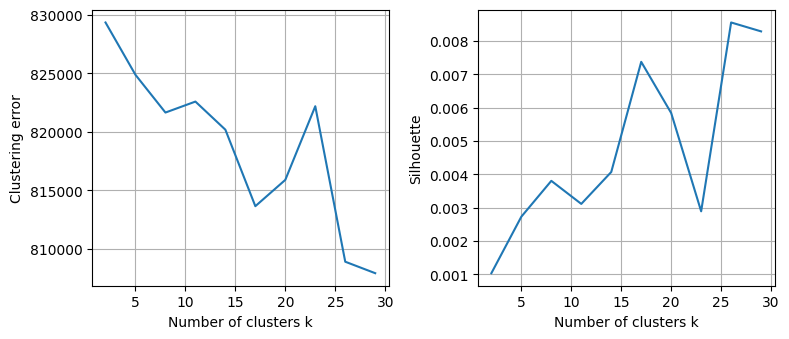

In [13]:
n_clusters=2
kmeans = KMeans(
    n_clusters, #will be choosen later
    #init='random', #centroids are initialized randomly TOO SLOW
    init='k-means++', #centroids are equally spaced -> probably better than random initialization. and should converge faster
    random_state=None, 
    n_init='auto', #number of times the k-means algorithm will be run with different centroid seeds. 'auto' uses a default value based on init
    max_iter=300
    )
kmeans_results = []
k_values=pd.Series(range(2, 30, 3))#this will need to be changed
for k in k_values:
    kmeans_results.append(KMeans(n_clusters=k).fit(vectorizedData))
    #print(f"Fitted KMeans with {k} clusters")#just to have a reference to how much time it's taking to execute

n_sample=100000
silhouetteScores = []
for result in kmeans_results:
    #print(len(np.unique(result.labels_)))
    try:
        silhouetteScores.append(silhouette_score(vectorizedData, result.labels_, sample_size=n_sample))
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)
    
plot_clustering_error_and_silhouette(kmeans_results,silhouetteScores)

<h2>User Distribution Analysis</h2>

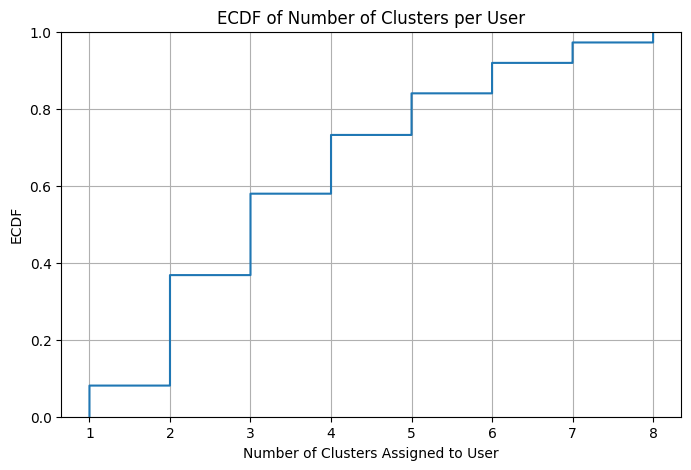

In [14]:
#print(kmeans_results[1].labels_)
indexOfChoosenCluster=2
numberOfChoosenClusters=k_values[indexOfChoosenCluster]
#data.insert(loc=1,column="cluster",value=kmeans_results[indexOfChoosenCluster].labels_)#adding labels to each comment
data["cluster"]= kmeans_results[indexOfChoosenCluster].labels_
user_clusters = data.groupby('author')['cluster'].nunique().reset_index()#grouping by author
#user clusters is now a series with author and number of clusters
user_clusters.columns = ['author', 'num_clusters']#turn it into a DF

# Filter user_clusters to only those authors who have multiple comments
authors_with_multiple_comments = data.groupby('author')['body'].nunique()
authors_with_multiple_comments = authors_with_multiple_comments[authors_with_multiple_comments > 1].index
user_clusters = user_clusters[user_clusters['author'].isin(authors_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=user_clusters, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to User')
plt.ylabel('ECDF')
plt.title('ECDF of Number of Clusters per User')
plt.grid(True)
plt.show()

In [15]:
#TODO
#Use the first two components of the PCA (found in Section 1.4). Then visualize on these two dimensions to gain insights into their distribution and separability.

<h3>Cluster analysis</h3>

In [16]:
!pip install WordCloud


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip


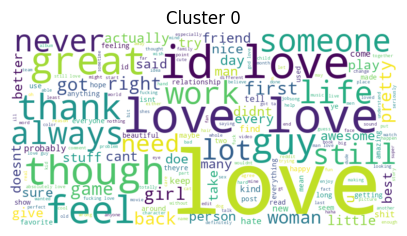

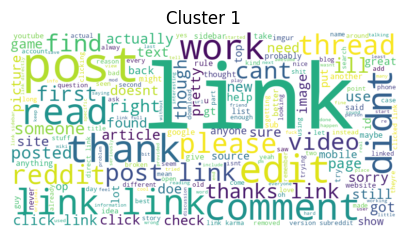

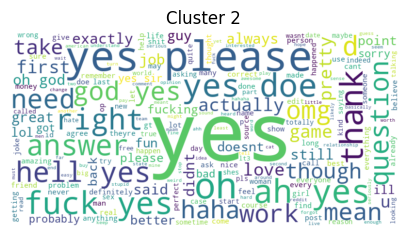

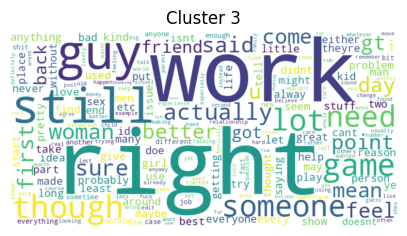

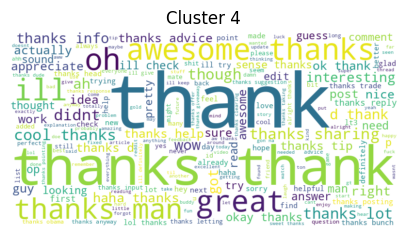

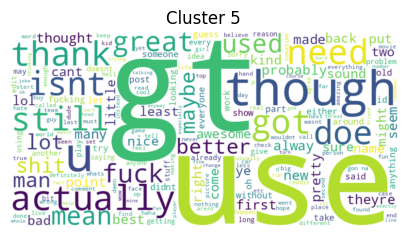

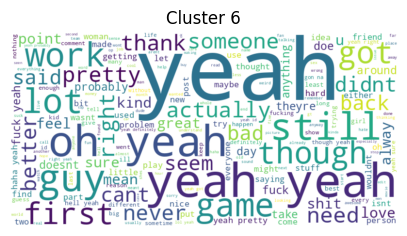

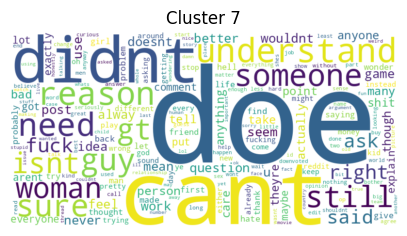

In [17]:
texts = []
# Generate and display word clouds for each cluster
for i in range(0, numberOfChoosenClusters):
    texts.append(" ".join(data[data['cluster'] == i]['body'].values))
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(texts[i])

    plt.figure(figsize=(5, 3))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title(f"Cluster {i}")
    plt.show()

In the word clouds above we just put the most frequent words. Meaning there are word present in every cloud e.g. "one"

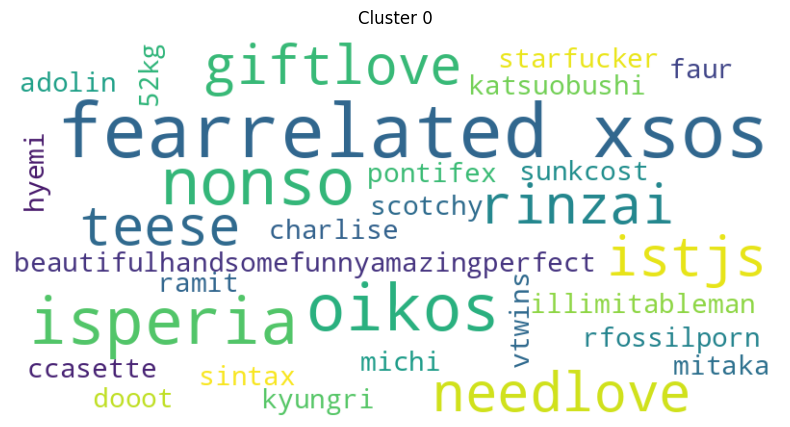

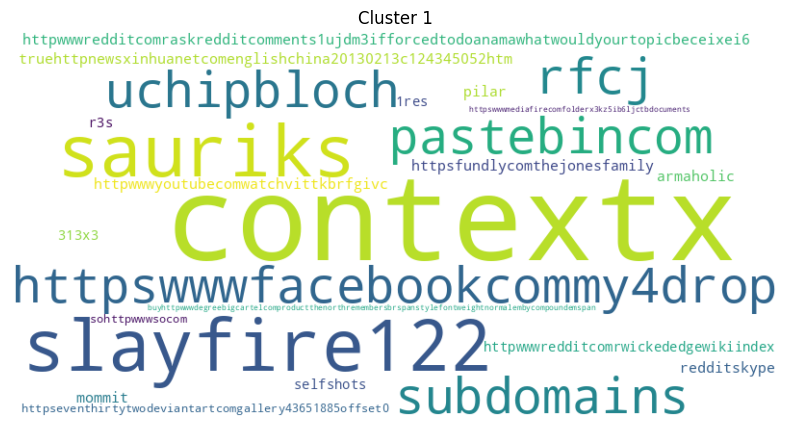

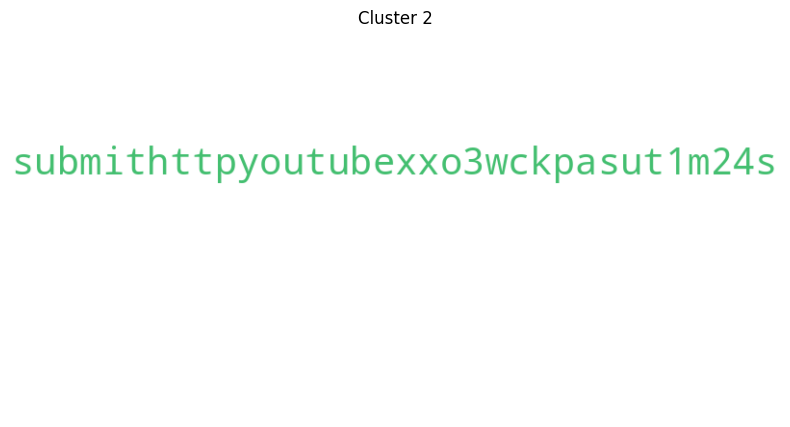

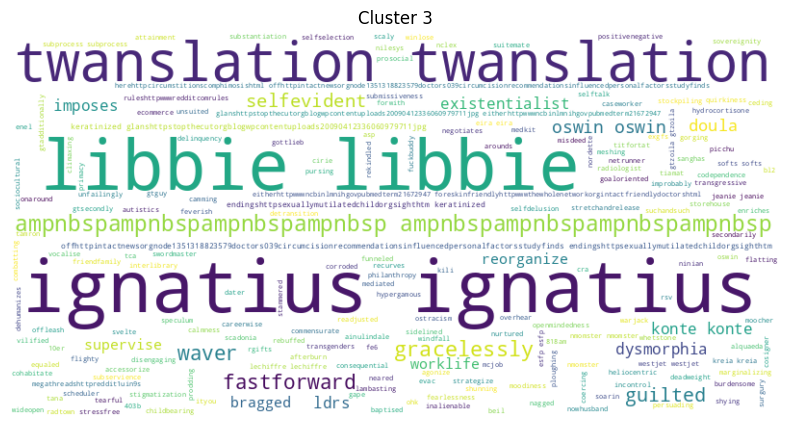

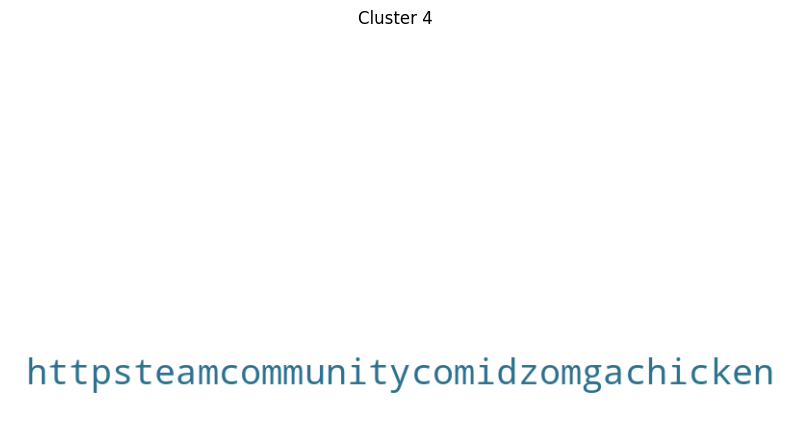

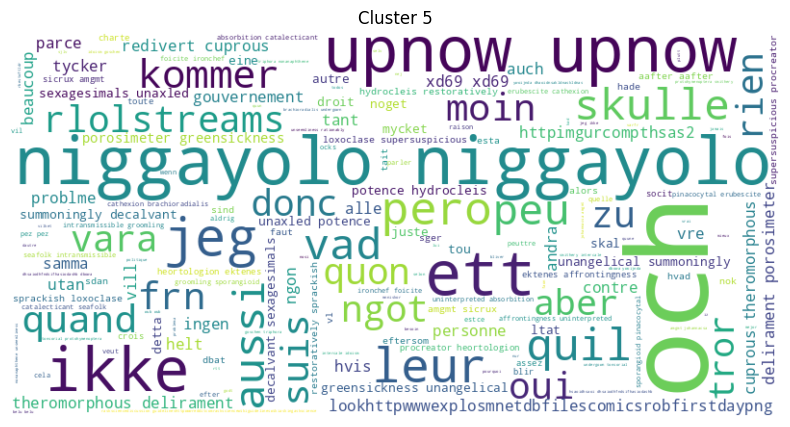

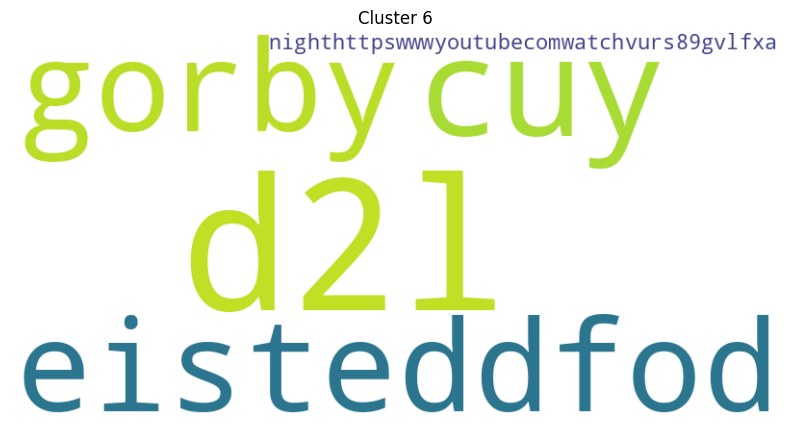

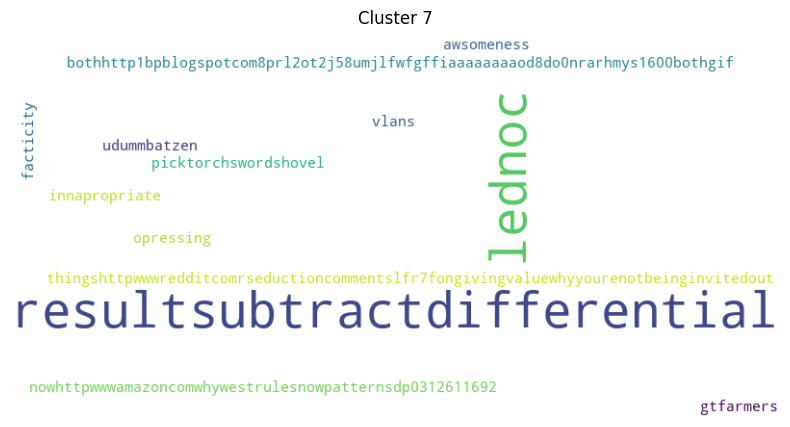

In [18]:
centroids = pd.DataFrame(
    kmeans_results[indexOfChoosenCluster].cluster_centers_,
    columns= sorted(vectorizer.vocabulary_, key=vectorizer.vocabulary_.get)
)
# we want to only keep the features (columns) that have only one value different from 0
#meaning that we are only keeping the words that are present in one single cluster
listOfRelevantWords= centroids.loc[:, (centroids != 0).sum() == 1].dropna(axis=1).columns.tolist()
# Remove all words not in listOfRelevantWords from each string in texts
filtered_texts = []
relevant_set = set(listOfRelevantWords)
for t in texts:
    filtered = " ".join([w for w in t.split() if w in relevant_set])
    filtered_texts.append(filtered)

for i in range(0, numberOfChoosenClusters):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(filtered_texts[i])

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f"Cluster {i}")
    plt.axis('off')  
    plt.show()

<h2>Subreddit distribution</h2>

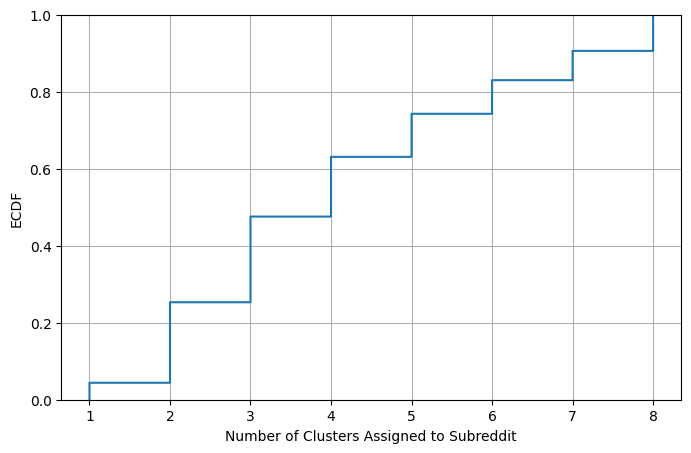

In [19]:
subreddit_cluster = data.groupby('subreddit')['cluster'].nunique().reset_index()#grouping by subreddit
#subreddit clusters is now a series with subreddit and number of clusters
subreddit_cluster.columns = ['subreddit', 'num_clusters']#turn it into a DF

# Filter subreddit_cluster to only those subreddits that have multiple comments
subreddits_with_multiple_comments = data.groupby('subreddit')['body'].nunique()
subreddits_with_multiple_comments = subreddits_with_multiple_comments[subreddits_with_multiple_comments > 1].index
subreddit_cluster = subreddit_cluster[subreddit_cluster['subreddit'].isin(subreddits_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=subreddit_cluster, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to Subreddit')
plt.ylabel('ECDF')
plt.grid(True)
plt.show()

Cluster 0:


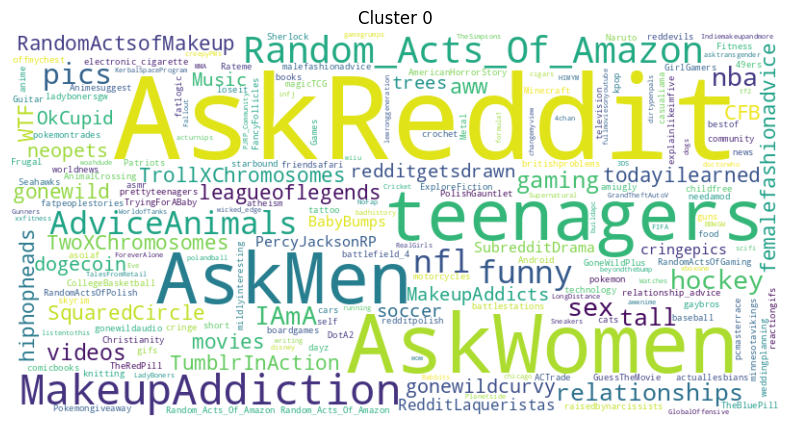

Cluster 1:


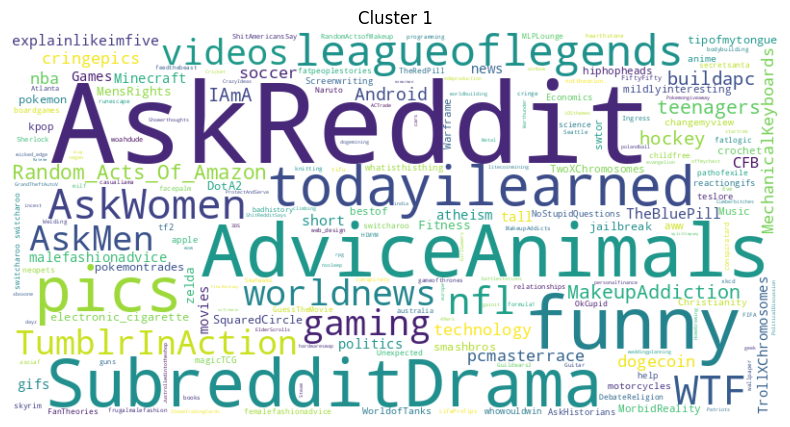

Cluster 2:


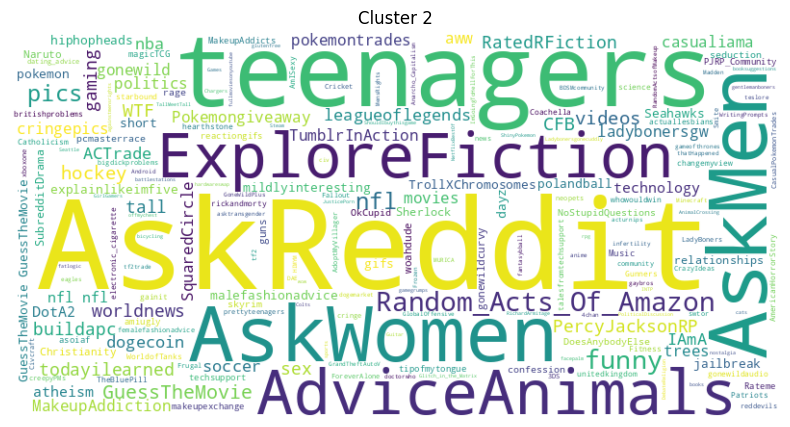

Cluster 3:


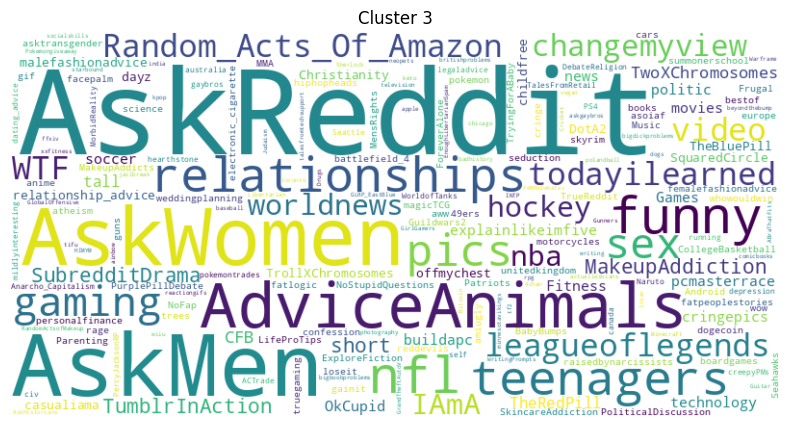

Cluster 4:


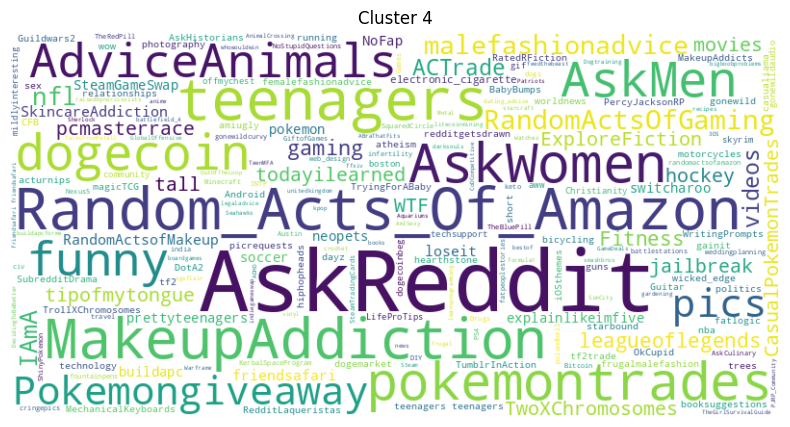

Cluster 5:


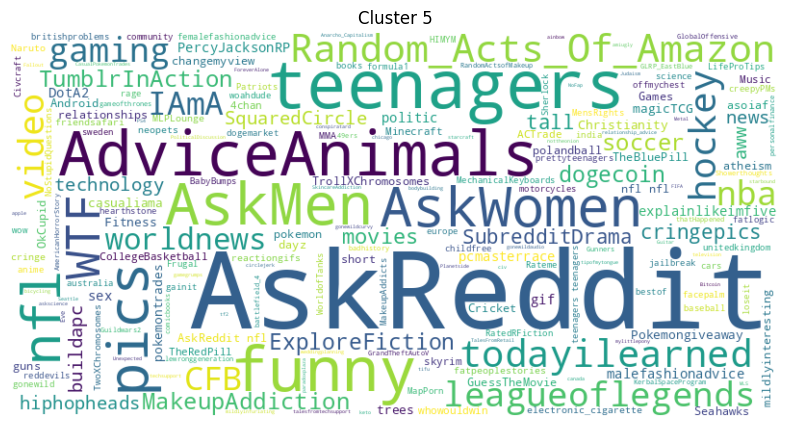

Cluster 6:


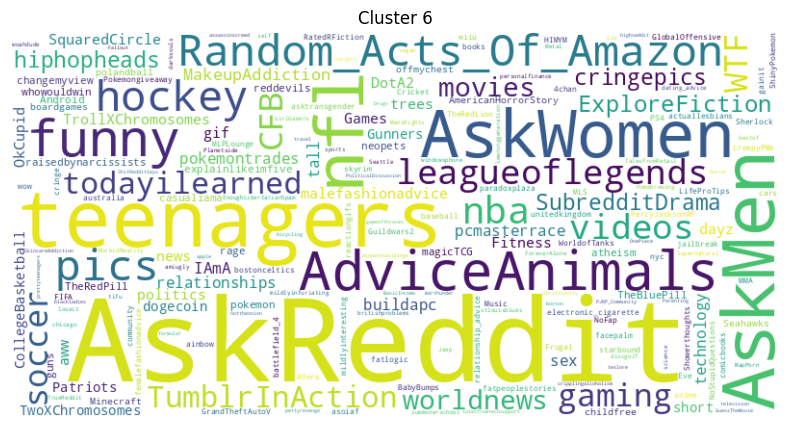

Cluster 7:


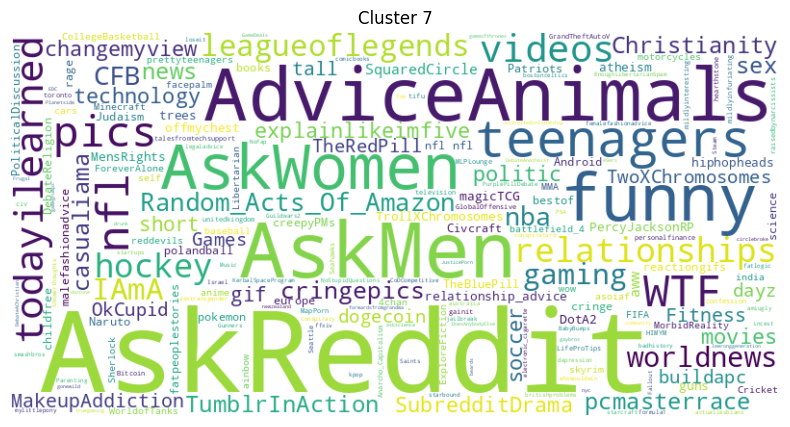

In [20]:
subredditsNames = []
for i in range(0, numberOfChoosenClusters):
    print(f"Cluster {i}:")
    subredditsNames.append(" ".join(data[data['cluster'] == i]['subreddit'].values))
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(subredditsNames[i])

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title(f"Cluster {i}")
    plt.show()